# Diabetes Status Classification from BRFSS 2015 Health Indicators

This notebook classifies survey respondents as no diabetes (0), prediabetes (1) or diabetes (2) from 21 health and lifestyle indicators in the CDC BRFSS 2015 data. It compares traditional machine learning (scikit-learn) with deep learning (TensorFlow/Keras, using `tf.data`) across 15 experiments plus a final test-set evaluation.

**Dataset:** CDC BRFSS 2015, Diabetes Health Indicators (253,680 rows). The raw data is not stored in this repository; download it from the Drive folder and upload the zip when the notebook asks.

**Links:** GitHub: https://github.com/denyseishimirwe/diabetes-brfss-classification | Drive: https://drive.google.com/drive/folders/1WTICaxd-hlayD76dvGgG38G59Mxlnz9g?usp=drive_link Video: (add link after recording)

**Setup:** random seeds are fixed (`SEED = 42`) and package versions are listed in `requirements.txt`.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 1. Data loading and quality checks
This section loads the dataset and checks its shape, class counts, missing values, duplicate rows and data types before any modelling. These checks decide which cleaning steps are needed later.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving diabetes_012_health_indicators_BRFSS2015.csv.zip to diabetes_012_health_indicators_BRFSS2015.csv (2).zip


In [ ]:
import pandas as pd

df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv.zip")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [ ]:

# Display all column names
print(df.columns.tolist())

# Count the number of records in each diabetes-status class
print(df["Diabetes_012"].value_counts().sort_index())

['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


In [ ]:

# Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check data types
print(df.dtypes)

Missing values per column:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64
Duplicate rows: 23899
Diabetes_012            float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholCons

**Interpretation.** The dataset has 253,680 rows and 22 columns with no missing values, so no imputation is needed. All columns are stored as float64 even though most are binary or ordinal codes, so I convert them to int8 later. There are 23,899 exact duplicate rows (9.4%), which need handling before the split.

## 2. Exploratory analysis
The bar chart shows how the three diabetes classes are distributed. The imbalance seen here determines which evaluation metrics can be trusted in the rest of the notebook.



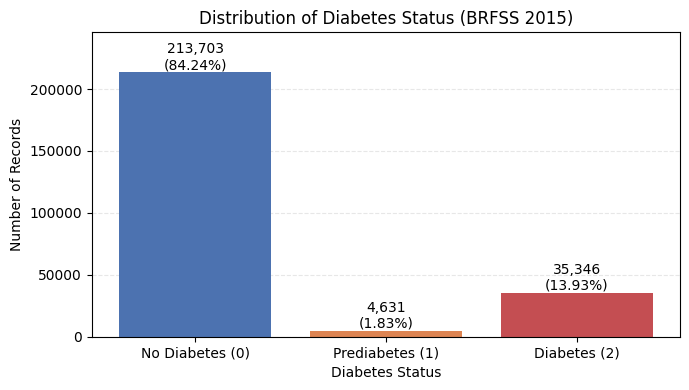

In [ ]:

import matplotlib.pyplot as plt

labels = ["No Diabetes (0)", "Prediabetes (1)", "Diabetes (2)"]
counts = df["Diabetes_012"].value_counts().sort_index()
pcts = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, counts.values, color=["#4C72B0", "#DD8452", "#C44E52"])

for bar, n, p in zip(bars, counts.values, pcts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{n:,}\n({p:.2f}%)", ha="center", va="bottom")

ax.set_title("Distribution of Diabetes Status (BRFSS 2015)")
ax.set_xlabel("Diabetes Status")
ax.set_ylabel("Number of Records")
ax.set_ylim(0, counts.max() * 1.15)  # room for the labels
ax.set_axisbelow(True)               # draw grid behind the bars
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation.** The classes are heavily imbalanced: 84.2% no diabetes, 13.9% diabetes and only 1.8% prediabetes (4,631 rows). A model that always predicts "no diabetes" would reach about 84% accuracy while missing every positive case, so accuracy is not a useful metric here. I use macro-F1, balanced accuracy, per-class recall and one-vs-rest ROC-AUC and PR-AUC instead.


## 3. Preprocessing and data split
This section removes exact duplicate rows before splitting, so that identical respondents cannot appear in both training and test data. It converts the integer-coded columns from float64 to int8, inspects BMI for implausible values, and creates a stratified 70/15/15 train/validation/test split (seed 42). BMI is then clipped to 12-60 using a fixed rule that uses no information from the validation or test sets.

In [ ]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df):,} duplicates -> {len(df):,} rows remain")

# Integer-coded categories were stored as float64
df = df.astype({c: "int8" for c in df.columns if c != "BMI"})
df["BMI"] = df["BMI"].astype("float32")

print(df["Diabetes_012"].value_counts().sort_index())

Removed 23,899 duplicates -> 229,781 rows remain
Diabetes_012
0    190055
1      4629
2     35097
Name: count, dtype: int64


**Interpretation.** Removing 23,899 duplicates leaves 229,781 rows. The prediabetes class is almost untouched (4,631 to 4,629), so the duplicates were mostly healthy and diabetes rows. Identical rows in both training and test data would inflate scores, which is why I remove them before splitting. Some duplicates may be genuinely different people with identical answers, so this is a trade-off that favours clean evaluation.

count    229781.000000
mean         28.685671
std           6.785429
min          12.000000
25%          24.000000
50%          27.000000
75%          32.000000
max          98.000000
Name: BMI, dtype: float64
BMI > 60: 805 | BMI > 80: 279


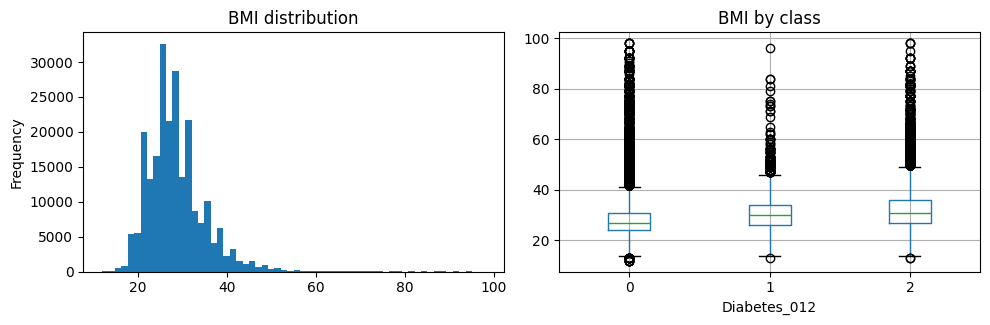

In [ ]:
print(df["BMI"].describe())
print("BMI > 60:", (df["BMI"] > 60).sum(), "| BMI > 80:", (df["BMI"] > 80).sum())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["BMI"].plot.hist(bins=60, ax=ax[0], title="BMI distribution")
df.boxplot(column="BMI", by="Diabetes_012", ax=ax[1])
ax[1].set_title("BMI by class"); plt.suptitle("")
plt.tight_layout(); plt.show()

**Interpretation.** BMI has a right-skewed distribution (mean 28.7, median 27) with a long tail up to 98. 805 rows exceed 60 and 279 exceed 80, which are very unlikely to be accurate self-reports. I clip rather than drop these rows because the dataset has few prediabetes cases to lose.

In [ ]:
X = df.drop(columns="Diabetes_012")
y = df["Diabetes_012"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(name, len(part), (part.value_counts(normalize=True).sort_index() * 100).round(2).tolist())

train 160846 [82.71, 2.01, 15.27]
val 34467 [82.71, 2.02, 15.27]
test 34468 [82.71, 2.01, 15.28]


**Interpretation.** The stratified split gives 160,846 training, 34,467 validation and 34,468 test rows, with nearly identical class proportions in each (about 82.7%, 2.0% and 15.3%). The validation and test sets each contain only about 695 prediabetes cases, so per-class results for that class will be noisy.

In [ ]:
print(X_train["BMI"].quantile([0.001, 0.005, 0.01, 0.99, 0.995, 0.999]))

0.001    16.0
0.005    17.0
0.010    18.0
0.990    50.0
0.995    56.0
0.999    81.0
Name: BMI, dtype: float64


In [ ]:
CLIP_LO, CLIP_HI = 12, 60   # fixed upper bound; see the quantile table above

for part in (X_train, X_val, X_test):
    part["BMI"] = part["BMI"].clip(CLIP_LO, CLIP_HI)

print(X_train["BMI"].describe())

count    160846.000000
mean         28.635334
std           6.424443
min          12.000000
25%          24.000000
50%          27.000000
75%          32.000000
max          60.000000
Name: BMI, dtype: float64


**Interpretation.** The quantile table shows the 99.5th percentile at 56 but the 99.9th at 81, so a percentile cap would leave many implausible values. I use a fixed upper bound of 60, which changes only about 0.3% of rows and lowers the maximum from 98 to 60. The bound is a fixed rule that uses no information from the validation or test sets.

## 4. Feature engineering and correlations
Five features are derived from existing columns: a BMI category, a count of chronic conditions, a healthy-lifestyle score, total unhealthy days, and an Age x BMI interaction. They are built after the split from each row's own values, so they leak nothing. Correlations with the target are computed on the training set only, and the engineered features are tested in separate experiments to see whether they help.

In [ ]:
def add_features(X):
    X = X.copy()
    # WHO BMI categories: 0 under, 1 normal, 2 over, 3 obese I, 4 obese II, 5 obese III
    X["BMI_cat"] = np.digitize(X["BMI"], [18.5, 25, 30, 35, 40]).astype("int8")
    # Count of chronic conditions / impairments
    X["Health_burden"] = (X["HighBP"] + X["HighChol"] + X["Stroke"]
                          + X["HeartDiseaseorAttack"] + X["DiffWalk"]).astype("int8")
    # Healthy-behaviour score
    X["Lifestyle"] = (X["PhysActivity"] + X["Fruits"] + X["Veggies"]
                      + (1 - X["Smoker"]) + (1 - X["HvyAlcoholConsump"])).astype("int8")
    # Total unhealthy days in the past month
    X["Poor_days"] = (X["MentHlth"] + X["PhysHlth"]).astype("int8")
    # Age and weight interact in diabetes risk
    X["Age_x_BMI"] = (X["Age"] * X["BMI"]).astype("float32")
    return X

X_train_fe = add_features(X_train)
X_val_fe   = add_features(X_val)
X_test_fe  = add_features(X_test)

print(X_train.shape, "->", X_train_fe.shape)

(160846, 21) -> (160846, 26)


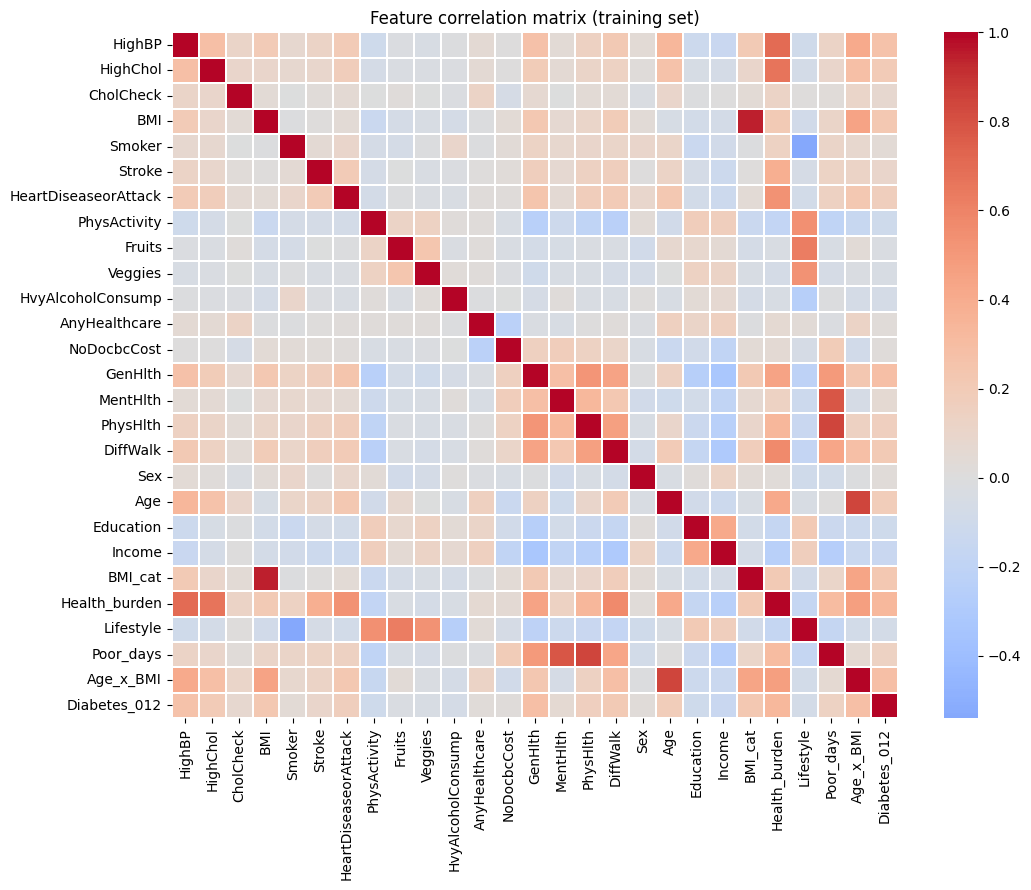

Health_burden           0.335
Age_x_BMI               0.289
GenHlth                 0.282
HighBP                  0.261
BMI_cat                 0.221
BMI                     0.220
DiffWalk                0.209
HighChol                0.203
Age                     0.185
HeartDiseaseorAttack    0.169
PhysHlth                0.159
Poor_days               0.137
Stroke                  0.101
CholCheck               0.074
MentHlth                0.058
Smoker                  0.046
Sex                     0.031
AnyHealthcare           0.027
NoDocbcCost             0.023
Fruits                 -0.023
Veggies                -0.043
HvyAlcoholConsump      -0.067
Lifestyle              -0.075
Education              -0.104
PhysActivity           -0.104
Income                 -0.144
Name: Diabetes_012, dtype: float64


In [ ]:
import seaborn as sns

corr_df = X_train_fe.assign(Diabetes_012=y_train)
corr = corr_df.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Feature correlation matrix (training set)")
plt.tight_layout(); plt.show()

print(corr["Diabetes_012"].drop("Diabetes_012").sort_values(ascending=False).round(3))

**Interpretation.** The strongest correlation with the target is the engineered `Health_burden` (0.335), followed by `Age_x_BMI` (0.289), `GenHlth` (0.282) and `HighBP` (0.261). Most features are below 0.2, so the signal is weak and I expect a modest performance ceiling. Several features are strongly correlated with each other (BMI with BMI_cat, Age with Age_x_BMI, MentHlth with PhysHlth and Poor_days), which matters for interpreting linear coefficients. Pearson correlation treats the three classes as an ordered numeric scale, so these values are only a first look.

## 5. Evaluation helper
`evaluate()` scores every model in the same way: macro-F1, balanced accuracy, per-class recall, precision for prediabetes, one-vs-rest ROC-AUC and PR-AUC, and a confusion matrix. Each call adds a row to `results`, which becomes the experiment table. Plain accuracy is deliberately not reported, since always predicting "no diabetes" already scores about 83%.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, recall_score, precision_score,
                             balanced_accuracy_score, roc_auc_score,
                             average_precision_score, confusion_matrix)

results = []   # one row per experiment -> becomes your experiment table

def evaluate(exp_id, name, model, Xv, yv, params="", notes=""):
    proba = model.predict_proba(Xv)
    pred = proba.argmax(axis=1)
    yb = label_binarize(yv, classes=[0, 1, 2])
    rec = recall_score(yv, pred, average=None)
    prec = precision_score(yv, pred, average=None, zero_division=0)
    row = {
        "Exp": exp_id, "Model": name, "Params": params,
        "Macro-F1": f1_score(yv, pred, average="macro"),
        "Bal.Acc": balanced_accuracy_score(yv, pred),
        "Recall_0": rec[0], "Recall_1": rec[1], "Recall_2": rec[2],
        "Prec_1": prec[1],
        "ROC-AUC (macro OvR)": roc_auc_score(yb, proba, average="macro"),
        "PR-AUC (macro)": average_precision_score(yb, proba, average="macro"),
        "Notes": notes,
    }
    results.append(row)
    print(pd.Series(row).drop(["Params", "Notes"]).round(3).to_string())
    print(confusion_matrix(yv, pred))

## 6. Classical ML experiments (E1-E8)
E1-E3 use logistic regression (baseline, class-weighted, and with engineered features). E4-E5 use a random forest, with the second tuned by randomized search on a 40,000-row subsample. E6-E7 use histogram gradient boosting with and without the engineered features. E8 rescales the probabilities of the unweighted logistic regression to change the decision rule without retraining. Most experiments change a single thing so that differences can be traced to one cause.

In [ ]:
# Exp 1: baseline, original 21 features, no class weights
lr1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
lr1.fit(X_train, y_train)
evaluate("E1", "LogReg", lr1, X_val, y_val, "no class weights, 21 features")

# Exp 2: same features, balanced class weights
lr2 = make_pipeline(StandardScaler(),
                    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
lr2.fit(X_train, y_train)
evaluate("E2", "LogReg", lr2, X_val, y_val, "class_weight=balanced, 21 features")

# Exp 3: balanced weights + engineered features (isolates the effect of feature engineering)
lr3 = make_pipeline(StandardScaler(),
                    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
lr3.fit(X_train_fe, y_train)
evaluate("E3", "LogReg", lr3, X_val_fe, y_val, "class_weight=balanced, 26 engineered features")

Exp                          E1
Model                    LogReg
Macro-F1                0.39063
Bal.Acc                0.383286
Recall_0               0.975656
Recall_1                    0.0
Recall_2               0.174202
Prec_1                      0.0
ROC-AUC (macro OvR)    0.770241
PR-AUC (macro)         0.470013
[[27814     0   694]
 [  636     0    59]
 [ 4347     0   917]]
Exp                          E2
Model                    LogReg
Macro-F1                0.42718
Bal.Acc                0.515334
Recall_0               0.644381
Recall_1               0.303597
Recall_2               0.598024
Prec_1                 0.032522
ROC-AUC (macro OvR)    0.760703
PR-AUC (macro)         0.466048
[[18370  5057  5081]
 [  198   211   286]
 [  896  1220  3148]]
Exp                          E3
Model                    LogReg
Macro-F1               0.427755
Bal.Acc                0.515524
Recall_0               0.645328
Recall_1               0.313669
Recall_2               0.587576
Prec_1  

**Interpretation.** The unweighted baseline (E1) never predicts prediabetes (recall 0) and finds only 17% of diabetes cases, even though its ROC-AUC is 0.77, so the model ranks people reasonably but the decision rule favours the majority class. Class weights (E2) raise prediabetes recall to 0.30 and diabetes recall to 0.60 at the cost of healthy-class recall, which falls from 0.98 to 0.64. Engineered features (E3) change macro-F1 by only 0.001, so a linear model gains almost nothing from them.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# E4: Random Forest, balanced class weights, original features
rf4 = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                             class_weight="balanced_subsample",
                             n_jobs=-1, random_state=SEED)
rf4.fit(X_train, y_train)
evaluate("E4", "RandomForest", rf4, X_val, y_val,
         "300 trees, min_leaf=5, balanced_subsample, 21 features")

# E5: tune on a stratified 40k subsample, then refit best params on full train
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=40000,
                                      stratify=y_train, random_state=SEED)
search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=SEED),
    {"max_depth": [6, 10, 14, 20, None],
     "min_samples_leaf": [3, 5, 10, 20, 40],
     "max_features": ["sqrt", 0.3, 0.5]},
    n_iter=10, cv=3, scoring="f1_macro", random_state=SEED, n_jobs=1)
search.fit(X_sub, y_sub)
print("Best params:", search.best_params_)

rf5 = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                             n_jobs=-1, random_state=SEED, **search.best_params_)
rf5.fit(X_train, y_train)
evaluate("E5", "RandomForest-tuned", rf5, X_val, y_val, f"{search.best_params_}, 21 features")

Exp                              E4
Model                  RandomForest
Macro-F1                    0.44448
Bal.Acc                    0.486539
Recall_0                   0.799986
Recall_1                   0.005755
Recall_2                   0.653875
Prec_1                     0.022989
ROC-AUC (macro OvR)        0.754189
PR-AUC (macro)             0.468131
[[22806   135  5567]
 [  340     4   351]
 [ 1787    35  3442]]
Best params: {'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 14}
Exp                                    E5
Model                  RandomForest-tuned
Macro-F1                         0.444544
Bal.Acc                          0.495037
Recall_0                         0.754174
Recall_1                         0.041727
Recall_2                          0.68921
Prec_1                           0.030753
ROC-AUC (macro OvR)              0.748876
PR-AUC (macro)                   0.467598
[[21500   757  6251]
 [  303    29   363]
 [ 1479   157  3628]]


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

sw = compute_sample_weight("balanced", y_train)

# E6: HistGradientBoosting, weighted, original features
hgb6 = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=300, max_depth=6,
                                      early_stopping=True, random_state=SEED)
hgb6.fit(X_train, y_train, sample_weight=sw)
evaluate("E6", "HistGB", hgb6, X_val, y_val, "lr=0.1, depth=6, balanced sample weights, 21 features")

# E7: same model, engineered features
hgb7 = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=300, max_depth=6,
                                      early_stopping=True, random_state=SEED)
hgb7.fit(X_train_fe, y_train, sample_weight=sw)
evaluate("E7", "HistGB", hgb7, X_val_fe, y_val, "same, 26 engineered features")

Exp                          E6
Model                    HistGB
Macro-F1                 0.4207
Bal.Acc                  0.5081
Recall_0               0.623123
Recall_1               0.277698
Recall_2                0.62348
Prec_1                 0.029093
ROC-AUC (macro OvR)    0.757899
PR-AUC (macro)         0.472021
[[17764  5267  5477]
 [  186   193   316]
 [  808  1174  3282]]
Exp                          E7
Model                    HistGB
Macro-F1               0.419973
Bal.Acc                0.507641
Recall_0               0.622913
Recall_1                0.27482
Recall_2                0.62519
Prec_1                 0.029187
ROC-AUC (macro OvR)    0.757226
PR-AUC (macro)         0.470291
[[17758  5172  5578]
 [  181   191   323]
 [  792  1181  3291]]


In [ ]:
proba_val = lr1.predict_proba(X_val)

best_f1, best_w = 0, None
for s1 in np.logspace(0, 2, 25):        # scale for prediabetes
    for s2 in np.logspace(0, 1.5, 25):  # scale for diabetes
        pred = (proba_val * np.array([1, s1, s2])).argmax(axis=1)
        f = f1_score(y_val, pred, average="macro")
        if f > best_f1:
            best_f1, best_w = f, np.array([1, s1, s2])
print("Best macro-F1:", round(best_f1, 4), "scales:", best_w.round(2))

class Rescaled:
    """Wraps a fitted model and rescales class probabilities."""
    def __init__(self, base, w): self.base, self.w = base, w
    def predict_proba(self, X):
        p = self.base.predict_proba(X) * self.w
        return p / p.sum(axis=1, keepdims=True)

evaluate("E8", "LogReg + rescaling", Rescaled(lr1, best_w), X_val, y_val,
         f"unweighted LogReg, class scales tuned on val = {best_w.round(2)}")

Best macro-F1: 0.4614 scales: [ 1.   21.54  2.74]
Exp                                    E8
Model                  LogReg + rescaling
Macro-F1                         0.461397
Bal.Acc                          0.479061
Recall_0                         0.846604
Recall_1                         0.122302
Recall_2                         0.468275
Prec_1                           0.046246
ROC-AUC (macro OvR)               0.76748
PR-AUC (macro)                   0.468066
[[24135  1216  3157]
 [  399    85   211]
 [ 2262   537  2465]]


**Interpretation.** The random forests (E4, E5) have the highest macro-F1 among the weighted models (0.444 to 0.445) but find almost no prediabetes cases (recall 0.006 and 0.042), so macro-F1 alone can hide a failed class. Gradient boosting (E6, E7) performs no better than logistic regression, and the engineered features again change nothing. E8, which rescales the unweighted logistic regression's probabilities, reaches the best macro-F1 so far (0.461) by moving to a different trade-off, with higher healthy-class recall (0.85) and lower balanced accuracy (0.48).

In [ ]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump({"model": lr1, "class_scales": best_w}, "models/best_classical_logreg_rescaled.joblib")
pd.DataFrame(results).to_csv("experiment_results.csv", index=False)  # survives a Colab disconnect
pd.DataFrame(results).round(3)

,Exp,Model,Params,Macro-F1,Bal.Acc,Recall_0,Recall_1,Recall_2,Prec_1,ROC-AUC (macro OvR),PR-AUC (macro),Notes
0,E1,LogReg,"no class weights, 21 features",0.391,0.383,0.976,0.000,0.174,0.000,0.770,0.470,
1,E2,LogReg,"class_weight=balanced, 21 features",0.427,0.515,0.644,0.304,0.598,0.033,0.761,0.466,
2,E3,LogReg,"class_weight=balanced, 26 engineered features",0.428,0.516,0.645,0.314,0.588,0.032,0.760,0.467,
3,E4,RandomForest,"300 trees, min_leaf=5, balanced_subsample, 21 features",0.444,0.487,0.800,0.006,0.654,0.023,0.754,0.468,
4,E5,RandomForest-tuned,"{'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 14}, 21 features",0.445,0.495,0.754,0.042,0.689,0.031,0.749,0.468,
5,E6,HistGB,"lr=0.1, depth=6, balanced sample weights, 21 features",0.421,0.508,0.623,0.278,0.623,0.029,0.758,0.472,
6,E7,HistGB,"same, 26 engineered features",0.420,0.508,0.623,0.275,0.625,0.029,0.757,0.470,
7,E8,LogReg + rescaling,"unweighted LogReg, class scales tuned on val = [ 1. 21.54 2.74]",0.461,0.479,0.847,0.122,0.468,0.046,0.767,0.468,


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import shutil, os
dest = "/content/drive/MyDrive/diabetes_project"
os.makedirs(dest, exist_ok=True)

shutil.copy("models/best_classical_logreg_rescaled.joblib", dest)
shutil.copy("experiment_results.csv", dest)
print(os.listdir(dest))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['best_classical_logreg_rescaled.joblib', 'experiment_results.csv', 'best_dl_mlp_d1_unweighted.keras', 'dl_scaler_and_scales.joblib', 'second_dl_mlp_d2_weighted.keras', 'logs', 'requirements.txt']


## 7. Deep learning experiments (D1-D7)
Features are standardised using statistics from the training set only, and the data is fed through a `tf.data` pipeline. All models are Keras Functional-API networks. Training stops early on validation macro-F1 and not on validation loss, because with class weights the training loss is weighted and the validation loss is not, so the two cannot be compared. D1-D2 test class weighting, D3 the learning rate, D4 a larger network with dropout and L2, D5 focal loss, D6 engineered features, and D7 probability rescaling of the unweighted D1 network.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# Fit the scaler on training data only, then apply it to all three splits
scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train).astype("float32")
Xva = scaler.transform(X_val).astype("float32")
Xte = scaler.transform(X_test).astype("float32")
ytr, yva, yte = (y.values.astype("int32") for y in (y_train, y_val, y_test))

def make_ds(X, y, batch=512, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_ds(Xtr, ytr, training=True), make_ds(Xva, yva)

cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=ytr)
class_weight = dict(enumerate(cw))
print(class_weight)


{0: np.float64(0.40300766197126636), 1: np.float64(16.547942386831277), 2: np.float64(2.1823238901552156)}


In [ ]:
histories = {}

class KerasProba:
    """Lets the Keras model work with the same evaluate() helper as the sklearn models."""
    def __init__(self, m): self.m = m
    def predict_proba(self, X): return self.m.predict(X, batch_size=2048, verbose=0)

In [ ]:
from sklearn.metrics import f1_score

class MacroF1(keras.callbacks.Callback):
    """Computes validation macro-F1 each epoch so EarlyStopping can monitor it."""
    def __init__(self, X, y):
        super().__init__(); self.X, self.y = X, y
    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.X, batch_size=2048, verbose=0).argmax(1)
        logs["val_macro_f1"] = f1_score(self.y, pred, average="macro")

def focal_loss(gamma=2.0):
    def loss(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        p_t = tf.gather(y_pred, y_true, batch_dims=1)
        return tf.reduce_mean(tf.pow(1 - p_t, gamma) * -tf.math.log(p_t))
    return loss

def build_mlp(n_features, units=(128, 64), dropout=0.0, l2=0.0, lr=1e-3,
              loss="sparse_categorical_crossentropy"):
    keras.utils.set_random_seed(SEED)   # same initial weights every time
    reg = keras.regularizers.l2(l2) if l2 else None
    inp = keras.Input(shape=(n_features,))
    x = inp
    for u in units:
        x = layers.Dense(u, activation="relu", kernel_regularizer=reg)(x)
        if dropout:
            x = layers.Dropout(dropout)(x)
    out = layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss, metrics=["accuracy"])
    return model

def train(exp_id, model, class_weight=None, epochs=40, tr=None, va=None, Xv=None):
    tr, va = tr or train_ds, va or val_ds
    Xv = Xva if Xv is None else Xv
    cbs = [MacroF1(Xv, yva),   # must come before EarlyStopping
           keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max",
                                         patience=6, restore_best_weights=True),
           keras.callbacks.TensorBoard(log_dir=f"logs/{exp_id}")]
    histories[exp_id] = model.fit(tr, validation_data=va, epochs=epochs,
                                  class_weight=class_weight, callbacks=cbs, verbose=2)
    return model

In [ ]:
# D1: baseline MLP, no class weights
m1 = train("D1", build_mlp(Xtr.shape[1]))
evaluate("D1", "MLP 128-64", KerasProba(m1), Xva, yva, "no class weights, no dropout, lr=1e-3")

# D2: same architecture with class weights and dropout
m2 = train("D2", build_mlp(Xtr.shape[1], dropout=0.3), class_weight=class_weight)
evaluate("D2", "MLP 128-64", KerasProba(m2), Xva, yva, "balanced class weights, dropout=0.3")

Epoch 1/40
315/315 - 5s - 14ms/step - accuracy: 0.8300 - loss: 0.4493 - val_accuracy: 0.8360 - val_loss: 0.4263 - val_macro_f1: 0.4186
Epoch 2/40
315/315 - 2s - 7ms/step - accuracy: 0.8344 - loss: 0.4293 - val_accuracy: 0.8366 - val_loss: 0.4244 - val_macro_f1: 0.3896
Epoch 3/40
315/315 - 2s - 7ms/step - accuracy: 0.8349 - loss: 0.4278 - val_accuracy: 0.8366 - val_loss: 0.4234 - val_macro_f1: 0.3890
Epoch 4/40
315/315 - 3s - 8ms/step - accuracy: 0.8350 - loss: 0.4268 - val_accuracy: 0.8363 - val_loss: 0.4240 - val_macro_f1: 0.3842
Epoch 5/40
315/315 - 3s - 9ms/step - accuracy: 0.8355 - loss: 0.4258 - val_accuracy: 0.8359 - val_loss: 0.4243 - val_macro_f1: 0.4111
Epoch 6/40
315/315 - 3s - 10ms/step - accuracy: 0.8358 - loss: 0.4248 - val_accuracy: 0.8356 - val_loss: 0.4243 - val_macro_f1: 0.4079
Epoch 7/40
315/315 - 2s - 8ms/step - accuracy: 0.8361 - loss: 0.4243 - val_accuracy: 0.8367 - val_loss: 0.4245 - val_macro_f1: 0.3878
Exp                            D1
Model                  MLP

**Interpretation.** The unweighted network (D1) repeats E1: prediabetes recall is 0 and its ROC-AUC is 0.770. Class weights (D2) raise prediabetes recall to 0.24 and macro-F1 to 0.428, matching class-weighted logistic regression (E2, 0.427). The neural network therefore adds no clear benefit over the linear model on these features.

In [ ]:
# D3: D2 retrained with macro-F1 early stopping and a lower learning rate
m3 = train("D3", build_mlp(Xtr.shape[1], dropout=0.3, lr=3e-4), class_weight=class_weight)
evaluate("D3", "MLP 128-64", KerasProba(m3), Xva, yva,
         "class weights, dropout=0.3, lr=3e-4, stop on val macro-F1")

Epoch 1/40
315/315 - 5s - 16ms/step - accuracy: 0.5471 - loss: 1.0405 - val_accuracy: 0.5470 - val_loss: 0.9646 - val_macro_f1: 0.3906
Epoch 2/40
315/315 - 4s - 12ms/step - accuracy: 0.5679 - loss: 0.9972 - val_accuracy: 0.5855 - val_loss: 0.9088 - val_macro_f1: 0.4042
Epoch 3/40
315/315 - 4s - 13ms/step - accuracy: 0.5752 - loss: 0.9866 - val_accuracy: 0.5766 - val_loss: 0.9146 - val_macro_f1: 0.4047
Epoch 4/40
315/315 - 3s - 8ms/step - accuracy: 0.5793 - loss: 0.9810 - val_accuracy: 0.5855 - val_loss: 0.9081 - val_macro_f1: 0.4080
Epoch 5/40
315/315 - 7s - 21ms/step - accuracy: 0.5821 - loss: 0.9783 - val_accuracy: 0.5874 - val_loss: 0.9062 - val_macro_f1: 0.4102
Epoch 6/40
315/315 - 3s - 9ms/step - accuracy: 0.5887 - loss: 0.9758 - val_accuracy: 0.5742 - val_loss: 0.9180 - val_macro_f1: 0.4066
Epoch 7/40
315/315 - 3s - 9ms/step - accuracy: 0.5882 - loss: 0.9711 - val_accuracy: 0.5955 - val_loss: 0.8895 - val_macro_f1: 0.4131
Epoch 8/40
315/315 - 3s - 8ms/step - accuracy: 0.5892 - lo

In [ ]:
m4 = train("D4", build_mlp(Xtr.shape[1], units=(256, 128, 64), dropout=0.4, l2=1e-4, lr=3e-4),
           class_weight=class_weight)
evaluate("D4", "MLP 256-128-64", KerasProba(m4), Xva, yva,
         "class weights, dropout=0.4, L2=1e-4, lr=3e-4")

Epoch 1/40
315/315 - 6s - 19ms/step - accuracy: 0.5522 - loss: 1.0709 - val_accuracy: 0.6113 - val_loss: 0.9403 - val_macro_f1: 0.4125
Epoch 2/40
315/315 - 5s - 16ms/step - accuracy: 0.5792 - loss: 1.0292 - val_accuracy: 0.5976 - val_loss: 0.9321 - val_macro_f1: 0.4089
Epoch 3/40
315/315 - 5s - 17ms/step - accuracy: 0.5854 - loss: 1.0186 - val_accuracy: 0.5957 - val_loss: 0.9337 - val_macro_f1: 0.4083
Epoch 4/40
315/315 - 10s - 33ms/step - accuracy: 0.5947 - loss: 1.0129 - val_accuracy: 0.5997 - val_loss: 0.9189 - val_macro_f1: 0.4110
Epoch 5/40
315/315 - 5s - 15ms/step - accuracy: 0.5894 - loss: 1.0104 - val_accuracy: 0.6040 - val_loss: 0.9263 - val_macro_f1: 0.4127
Epoch 6/40
315/315 - 4s - 13ms/step - accuracy: 0.5942 - loss: 1.0071 - val_accuracy: 0.5925 - val_loss: 0.9430 - val_macro_f1: 0.4088
Epoch 7/40
315/315 - 7s - 22ms/step - accuracy: 0.5936 - loss: 1.0040 - val_accuracy: 0.5998 - val_loss: 0.9247 - val_macro_f1: 0.4140
Epoch 8/40
315/315 - 4s - 13ms/step - accuracy: 0.5912

In [ ]:
m5 = train("D5", build_mlp(Xtr.shape[1], dropout=0.3, lr=3e-4, loss=focal_loss(2.0)))
evaluate("D5", "MLP 128-64 focal", KerasProba(m5), Xva, yva,
         "focal loss gamma=2, no class weights, dropout=0.3, lr=3e-4")

Epoch 1/40
315/315 - 4s - 13ms/step - accuracy: 0.7941 - loss: 0.2078 - val_accuracy: 0.8320 - val_loss: 0.1616 - val_macro_f1: 0.3622
Epoch 2/40
315/315 - 6s - 19ms/step - accuracy: 0.8214 - loss: 0.1738 - val_accuracy: 0.8321 - val_loss: 0.1602 - val_macro_f1: 0.3496
Epoch 3/40
315/315 - 3s - 8ms/step - accuracy: 0.8270 - loss: 0.1694 - val_accuracy: 0.8310 - val_loss: 0.1596 - val_macro_f1: 0.3374
Epoch 4/40
315/315 - 3s - 8ms/step - accuracy: 0.8293 - loss: 0.1667 - val_accuracy: 0.8318 - val_loss: 0.1590 - val_macro_f1: 0.3445
Epoch 5/40
315/315 - 3s - 8ms/step - accuracy: 0.8303 - loss: 0.1648 - val_accuracy: 0.8331 - val_loss: 0.1584 - val_macro_f1: 0.3619
Epoch 6/40
315/315 - 5s - 15ms/step - accuracy: 0.8305 - loss: 0.1642 - val_accuracy: 0.8329 - val_loss: 0.1581 - val_macro_f1: 0.3506
Epoch 7/40
315/315 - 3s - 9ms/step - accuracy: 0.8311 - loss: 0.1639 - val_accuracy: 0.8341 - val_loss: 0.1583 - val_macro_f1: 0.3688
Epoch 8/40
315/315 - 3s - 9ms/step - accuracy: 0.8310 - los

In [ ]:
sc_fe = StandardScaler().fit(X_train_fe)
Xtr_fe = sc_fe.transform(X_train_fe).astype("float32")
Xva_fe = sc_fe.transform(X_val_fe).astype("float32")
tr_fe, va_fe = make_ds(Xtr_fe, ytr, training=True), make_ds(Xva_fe, yva)

m6 = train("D6", build_mlp(Xtr_fe.shape[1], dropout=0.3, lr=3e-4),
           class_weight=class_weight, tr=tr_fe, va=va_fe, Xv=Xva_fe)
evaluate("D6", "MLP 128-64 +FE", KerasProba(m6), Xva_fe, yva,
         "same as D3 with 26 engineered features")

Epoch 1/40
315/315 - 4s - 14ms/step - accuracy: 0.5491 - loss: 1.0437 - val_accuracy: 0.5677 - val_loss: 0.9293 - val_macro_f1: 0.4011
Epoch 2/40
315/315 - 4s - 13ms/step - accuracy: 0.5692 - loss: 0.9972 - val_accuracy: 0.6034 - val_loss: 0.8958 - val_macro_f1: 0.4107
Epoch 3/40
315/315 - 3s - 8ms/step - accuracy: 0.5801 - loss: 0.9864 - val_accuracy: 0.5939 - val_loss: 0.8956 - val_macro_f1: 0.4125
Epoch 4/40
315/315 - 3s - 9ms/step - accuracy: 0.5870 - loss: 0.9800 - val_accuracy: 0.5946 - val_loss: 0.8989 - val_macro_f1: 0.4136
Epoch 5/40
315/315 - 3s - 8ms/step - accuracy: 0.5862 - loss: 0.9776 - val_accuracy: 0.6045 - val_loss: 0.8952 - val_macro_f1: 0.4138
Epoch 6/40
315/315 - 3s - 11ms/step - accuracy: 0.5884 - loss: 0.9759 - val_accuracy: 0.6091 - val_loss: 0.8949 - val_macro_f1: 0.4156
Epoch 7/40
315/315 - 4s - 12ms/step - accuracy: 0.5906 - loss: 0.9724 - val_accuracy: 0.6176 - val_loss: 0.8766 - val_macro_f1: 0.4188
Epoch 8/40
315/315 - 3s - 8ms/step - accuracy: 0.5889 - lo

In [ ]:
proba_val = KerasProba(m1).predict_proba(Xva)

best_f1, best_w_dl = 0, None
for s1 in np.logspace(0, 2, 25):
    for s2 in np.logspace(0, 1.5, 25):
        pred = (proba_val * np.array([1, s1, s2])).argmax(axis=1)
        f = f1_score(yva, pred, average="macro")
        if f > best_f1:
            best_f1, best_w_dl = f, np.array([1, s1, s2])
print("Best val macro-F1:", round(best_f1, 4), "scales:", best_w_dl.round(2))

evaluate("D7", "MLP 128-64 + rescaling", Rescaled(KerasProba(m1), best_w_dl), Xva, yva,
         f"unweighted D1 network, class scales tuned on val = {best_w_dl.round(2)}")

Best val macro-F1: 0.4643 scales: [ 1.   14.68  2.37]
Exp                                        D7
Model                  MLP 128-64 + rescaling
Macro-F1                              0.46429
Bal.Acc                              0.486884
Recall_0                             0.831661
Recall_1                             0.077698
Recall_2                             0.551292
Prec_1                               0.046916
ROC-AUC (macro OvR)                  0.764779
PR-AUC (macro)                       0.470915
[[23709   787  4012]
 [  384    54   257]
 [ 2052   310  2902]]


**Interpretation.** A lower learning rate (D3, 0.417), a larger network with dropout and L2 (D4, 0.420) and engineered features (D6, 0.419) all stay within about 0.01 of D2 (0.428), which is within run-to-run variation. D4 has about four times as many parameters as D2 with no gain. Focal loss (D5) is the weakest, with macro-F1 0.371 and prediabetes recall 0, which suggests it needs a per-class weight to help the minority class. Rescaling the unweighted network's probabilities (D7, 0.464) ties with the equivalent logistic regression result (E8, 0.461).

## 8. Learning curves
For each network, the plots show training and validation loss, accuracy, and validation macro-F1 per epoch. They are used to judge whether a model is underfitting or overfitting and when early stopping selected its weights.

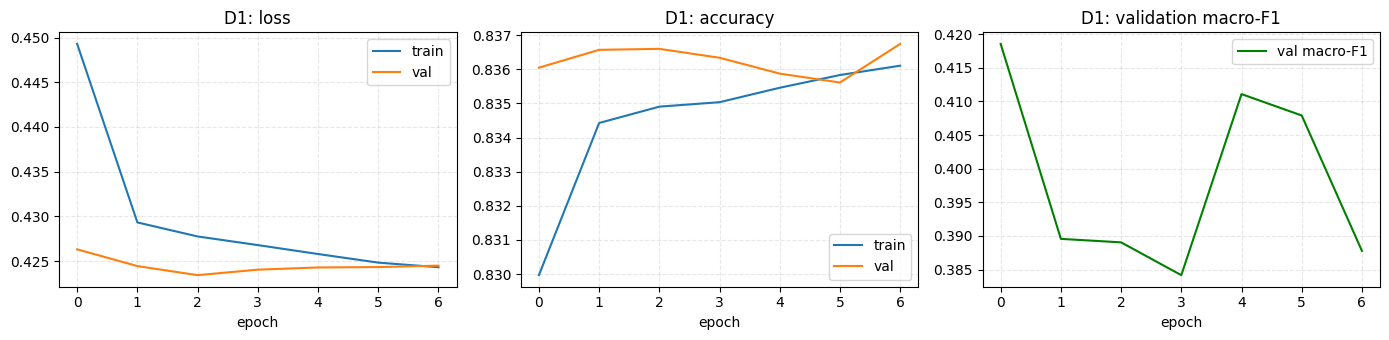

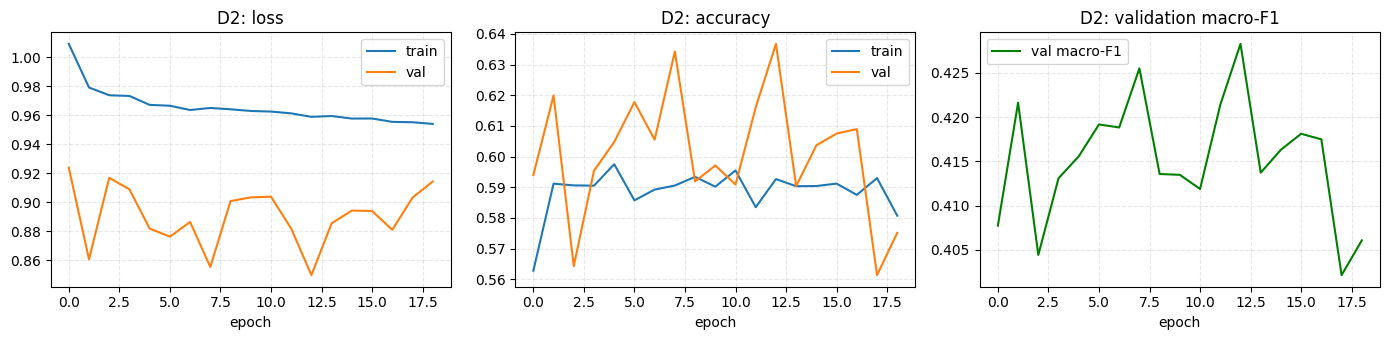

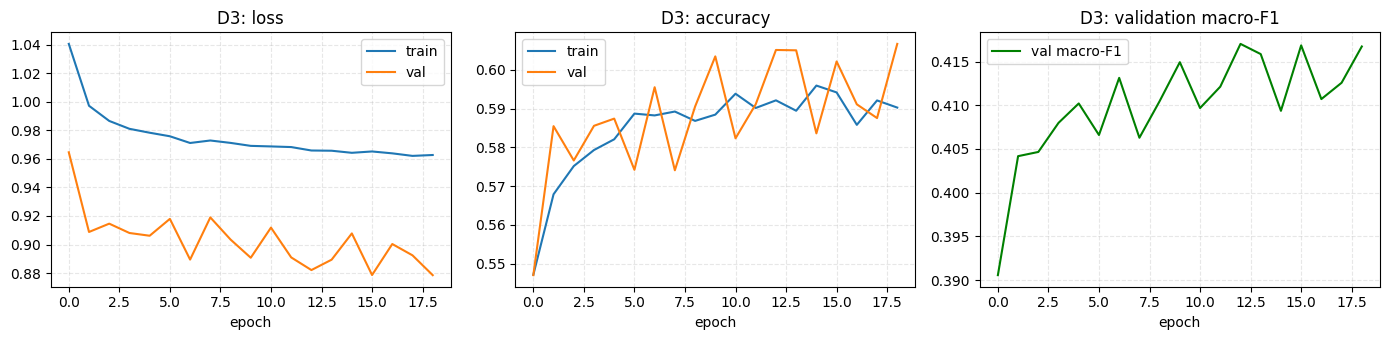

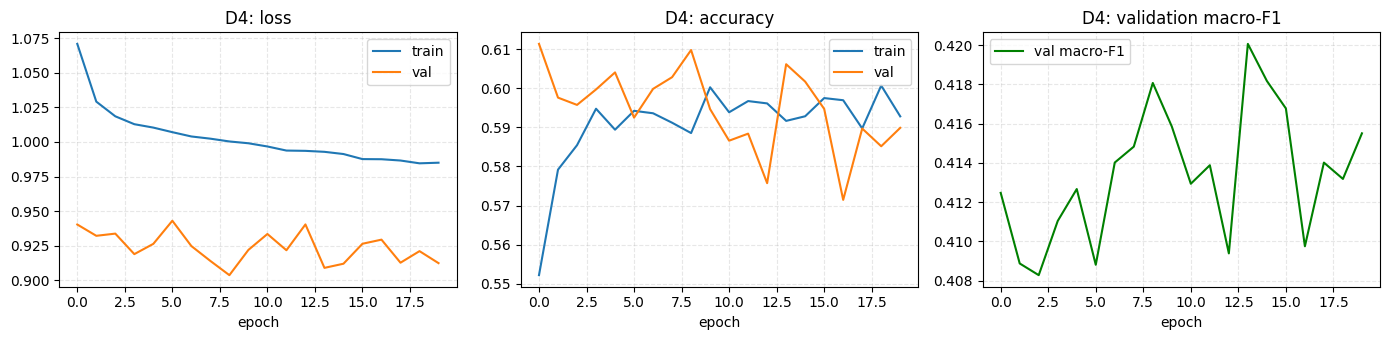

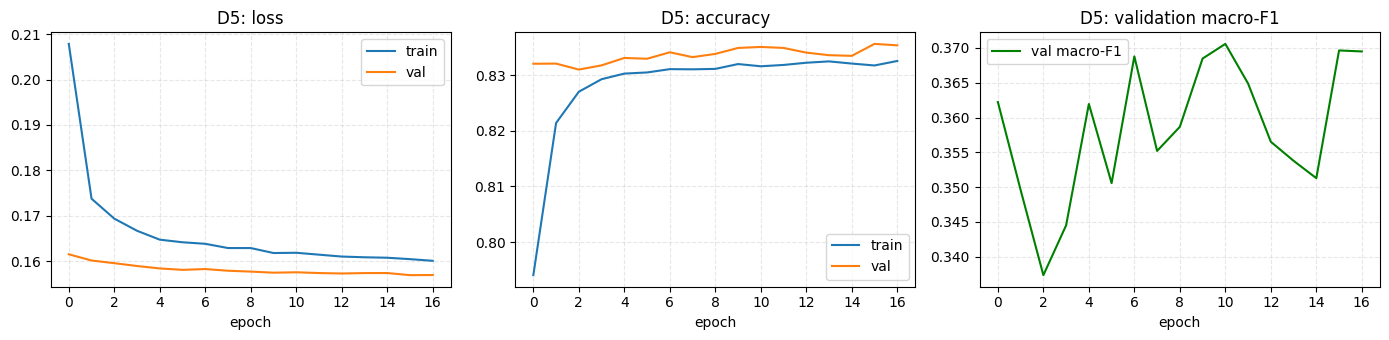

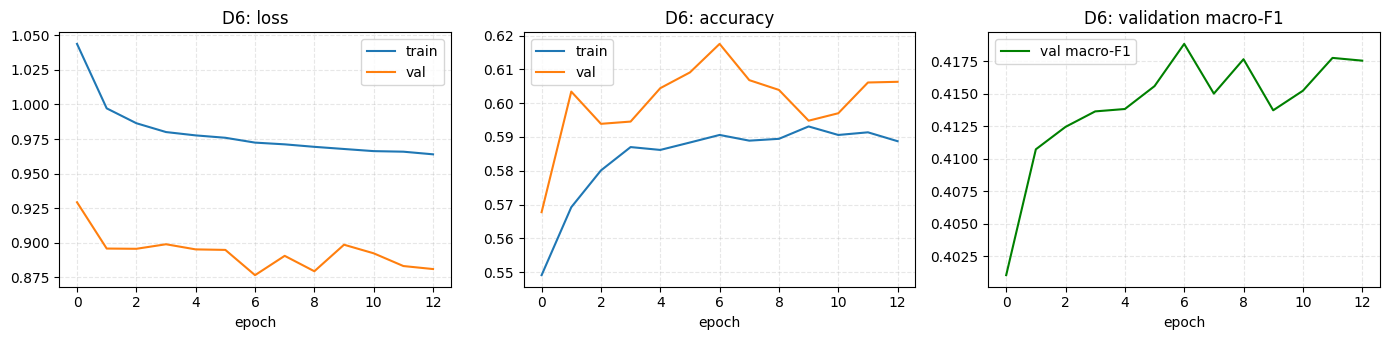

In [ ]:
def plot_curves(exp_id):
    h = histories[exp_id].history
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"{exp_id}: loss")
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
    ax[1].set_title(f"{exp_id}: accuracy")
    ax[2].plot(h["val_macro_f1"], label="val macro-F1", color="green")
    ax[2].set_title(f"{exp_id}: validation macro-F1")
    for a in ax:
        a.set_xlabel("epoch"); a.legend()
        a.set_axisbelow(True); a.grid(linestyle="--", alpha=0.3)
    plt.tight_layout(); plt.show()

for k in histories:
    plot_curves(k)

**Interpretation.** In every run the training and validation curves stay close together and neither loss shows a clear divergence, so the networks are not overfitting; the limit is the information in the features (high bias). For the class-weighted networks, training loss includes the class weights and validation loss does not, so the two cannot be compared directly, and their validation accuracy swings between about 0.56 and 0.64 from epoch to epoch because each prediabetes example carries a weight of about 16. Validation macro-F1 is noisy and flat: D2 peaked at epoch 13 (0.428), D3 at epoch 13 (0.417), D4 at epoch 14 (0.420) and D6 at epoch 7 (0.419), with epoch-to-epoch spreads of about 0.01-0.02, so the exact stopping epoch is partly luck. For the unweighted D1 the best macro-F1 came at epoch 1, while its validation loss was lowest at epoch 3, so that checkpoint (which D7 reuses) is a noisy choice.

## 9. Final test-set evaluation (T1-T3)
The test set is used once, after all model choices were made on validation data. E8 is the best classical model and D7 the best network by validation macro-F1; D2 is included as a second, more aggressive operating point. For each model the confusion matrix, one-vs-rest ROC curves and precision-recall curves are shown.

Exp                                         T1
Model                  LogReg + rescaling (E8)
Macro-F1                              0.458394
Bal.Acc                               0.476265
Recall_0                              0.843593
Recall_1                              0.118156
Recall_2                              0.467047
Prec_1                                0.045836
ROC-AUC (macro OvR)                   0.766858
PR-AUC (macro)                        0.467975
[[24050  1164  3295]
 [  409    82   203]
 [ 2263   543  2459]]


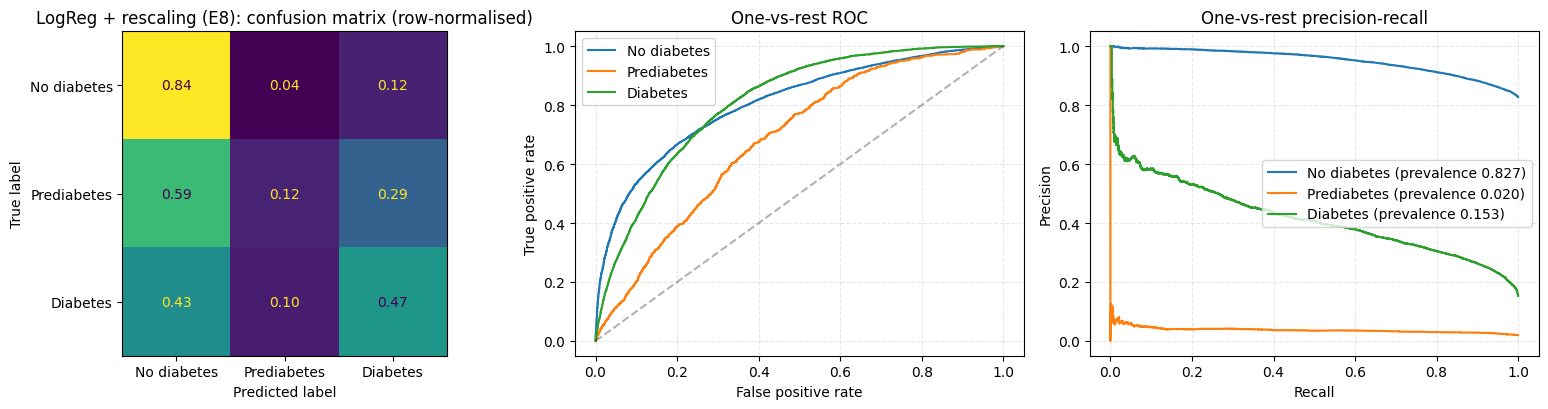

Exp                                      T2
Model                  MLP + rescaling (D7)
Macro-F1                           0.460175
Bal.Acc                            0.483061
Recall_0                           0.827248
Recall_1                           0.074928
Recall_2                           0.547009
Prec_1                             0.045455
ROC-AUC (macro OvR)                 0.76456
PR-AUC (macro)                     0.470064
[[23584   780  4145]
 [  395    52   247]
 [ 2073   312  2880]]


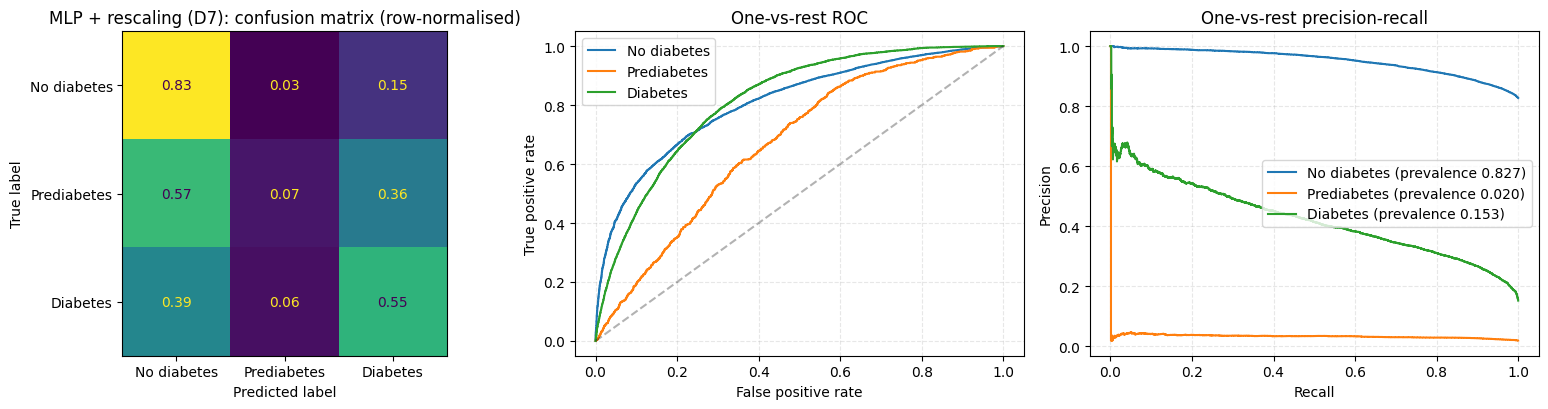

Exp                                         T3
Model                  MLP class-weighted (D2)
Macro-F1                              0.429617
Bal.Acc                               0.520937
Recall_0                              0.645305
Recall_1                              0.269452
Recall_2                              0.648053
Prec_1                                0.034124
ROC-AUC (macro OvR)                   0.767863
PR-AUC (macro)                        0.473052
[[18397  4308  5804]
 [  191   187   316]
 [  868   985  3412]]


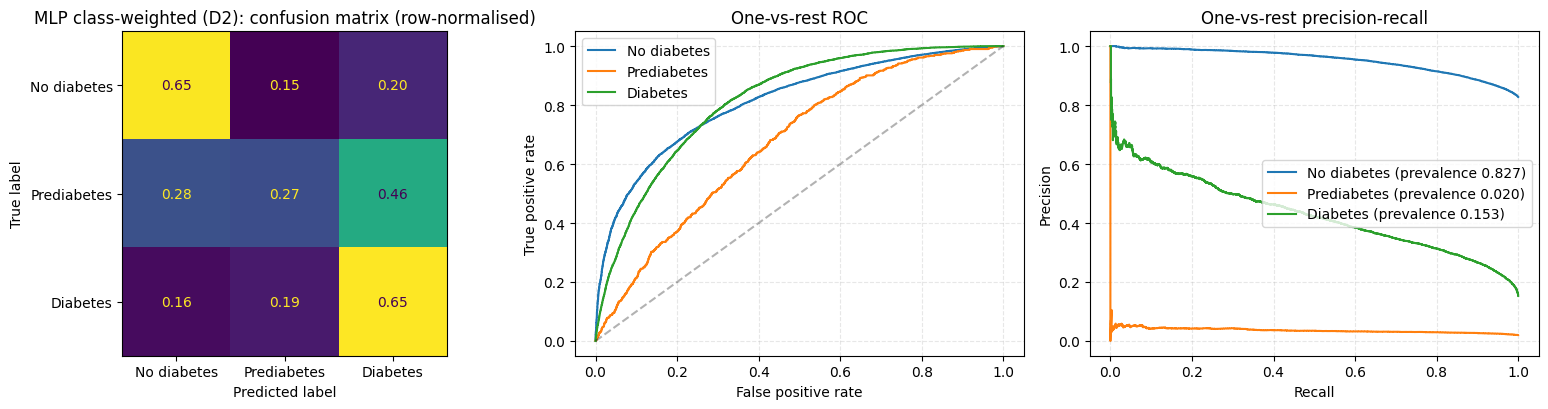

,Exp,Model,Params,Macro-F1,Bal.Acc,Recall_0,Recall_1,Recall_2,Prec_1,ROC-AUC (macro OvR),PR-AUC (macro),Notes
0,T1,LogReg + rescaling (E8),E8 model on the held-out test set,0.458,0.476,0.844,0.118,0.467,0.046,0.767,0.468,
1,T2,MLP + rescaling (D7),D7 model on the held-out test set,0.460,0.483,0.827,0.075,0.547,0.045,0.765,0.470,
2,T3,MLP class-weighted (D2),D2 model on the held-out test set,0.430,0.521,0.645,0.269,0.648,0.034,0.768,0.473,


In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay

names = ["No diabetes", "Prediabetes", "Diabetes"]

def final_report(tag, name, model, X, y, params):
    evaluate(tag, name, model, X, y, params)   # adds a row to results
    proba = model.predict_proba(X)
    pred = proba.argmax(axis=1)
    yb = label_binarize(y, classes=[0, 1, 2])

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    ConfusionMatrixDisplay.from_predictions(
        y, pred, display_labels=names, normalize="true",
        ax=ax[0], colorbar=False, values_format=".2f")
    ax[0].set_title(f"{name}: confusion matrix (row-normalised)")
    for k, n in enumerate(names):
        fpr, tpr, _ = roc_curve(yb[:, k], proba[:, k])
        ax[1].plot(fpr, tpr, label=n)
        p, r, _ = precision_recall_curve(yb[:, k], proba[:, k])
        ax[2].plot(r, p, label=f"{n} (prevalence {yb[:, k].mean():.3f})")
    ax[1].plot([0, 1], [0, 1], "k--", alpha=0.3)
    ax[1].set(title="One-vs-rest ROC", xlabel="False positive rate", ylabel="True positive rate")
    ax[2].set(title="One-vs-rest precision-recall", xlabel="Recall", ylabel="Precision")
    for a in ax[1:]:
        a.legend(); a.set_axisbelow(True); a.grid(linestyle="--", alpha=0.3)
    plt.tight_layout(); plt.show()

final_report("T1", "LogReg + rescaling (E8)", Rescaled(lr1, best_w), X_test, yte,
             "E8 model on the held-out test set")
final_report("T2", "MLP + rescaling (D7)", Rescaled(KerasProba(m1), best_w_dl), Xte, yte,
             "D7 model on the held-out test set")
final_report("T3", "MLP class-weighted (D2)", KerasProba(m2), Xte, yte,
             "D2 model on the held-out test set")

pd.DataFrame([r for r in results if r["Exp"].startswith("T")]).round(3)

**Interpretation.** Test macro-F1 is close to validation for all three models (E8 0.458, D7 0.460, D2 0.430), so tuning the class scales on validation did not inflate the results much. E8 and D7 are conservative: they flag about 1,800 and 1,100 people as prediabetic and catch 82 and 52 of the 694 true cases. D2 is more aggressive: it catches 187 cases and has the best balanced accuracy (0.521), but flags about 5,500 people, including roughly a third of healthy respondents. Which model is better depends on how costly a missed case is compared with a false alarm. ROC-AUC is about 0.765-0.768 for all three.

## 10. Results table and saving
This section assembles the full experiment table (settings, split, metrics and notes), saves it as `experiment_results.csv`, and copies the trained models, the scaler and class scales, the table and the TensorBoard logs to the Drive folder.

In [ ]:
import joblib, os, shutil

os.makedirs("models", exist_ok=True)
pd.DataFrame(results).drop_duplicates(subset="Exp", keep="last").to_csv("experiment_results.csv", index=False)

# Best deep learning model: D7 (the D1 network plus class rescaling) and its preprocessing
m1.save("models/best_dl_mlp_d1_unweighted.keras")
joblib.dump({"scaler": scaler, "class_scales": best_w_dl}, "models/dl_scaler_and_scales.joblib")
m2.save("models/second_dl_mlp_d2_weighted.keras")   # second operating point

for f in ["models/best_dl_mlp_d1_unweighted.keras", "models/dl_scaler_and_scales.joblib",
          "models/second_dl_mlp_d2_weighted.keras", "experiment_results.csv"]:
    shutil.copy(f, dest)
shutil.copytree("logs", dest + "/logs", dirs_exist_ok=True)
print(sorted(os.listdir(dest)))

['best_classical_logreg_rescaled.joblib', 'best_dl_mlp_d1_unweighted.keras', 'dl_scaler_and_scales.joblib', 'experiment_results.csv', 'logs', 'requirements.txt', 'second_dl_mlp_d2_weighted.keras']


In [ ]:
import importlib.metadata as md

pkgs = ["numpy", "pandas", "scikit-learn", "tensorflow", "keras",
        "matplotlib", "seaborn", "joblib"]
lines = [f"{p}=={md.version(p)}" for p in pkgs]

with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print("\n".join(lines))
shutil.copy("requirements.txt", dest)

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
tensorflow==2.21.0
keras==3.13.2
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0


'/content/drive/MyDrive/diabetes_project/requirements.txt'

In [ ]:
notes = {
    "E1": "The model achieved a ROC-AUC of 0.77, meaning it can distinguish between classes to some extent. However, it never predicted prediabetes as the most likely class, giving Recall_1 a value of 0. Since most people belong to class 0, the model tends to favour the majority class.",
    "E2": "Class weights helped the model identify more people with prediabetes and diabetes. Recall_1 increased from 0 to 0.304, while Recall_2 increased from 0.174 to 0.598. However, Recall_0 dropped from 0.976 to 0.644. ROC-AUC decreased slightly because class weighting changed the fitted coefficients, which affected how the model ranked its predictions.",
    "E3": "Macro-F1 barely changed, moving from 0.427 to 0.428. Most of the new features were combinations of existing columns, so they added little new information. BMI_cat and Age_x_BMI introduced some additional relationships, but they did not lead to a noticeable improvement.",
    "E4": "This model achieved a macro-F1 of 0.444, but Recall_1 was only 0.006, meaning it correctly identified very few people with prediabetes. The improvement came mainly from the other classes. Its balanced accuracy was 0.487, lower than E2's 0.515, showing that the higher macro-F1 did not mean better performance across all classes.",
    "E5": "Tuning barely changed the results, with macro-F1 increasing from 0.444 to 0.445, while ROC-AUC dropped from 0.754 to 0.749. Recall_1 increased from 0.006 to 0.042, and Recall_2 increased from 0.654 to 0.689, while Recall_0 fell from 0.800 to 0.754. This means tuning shifted predictions away from the healthy class towards both prediabetes and diabetes, although the overall improvement was very small.",
    "E6": "Macro-F1 was 0.421, compared with 0.427 for logistic regression in E2. This small difference does not show a meaningful improvement from using a more complex model. The results suggest that the available features may limit how much the model can improve.",
    "E7": "Macro-F1 changed only slightly, from 0.421 to 0.420. Adding manually created features did not improve the results, probably because boosted trees can already learn relationships between features on their own.",
    "E8": "Macro-F1 increased to 0.461, but the improvement was not shared across all classes. Recall_0 increased from 0.644 to 0.847, while Recall_1 dropped to 0.122. Balanced accuracy also fell to 0.479. Adjusting the probability scales changed the final predictions without retraining the model. Therefore, the higher macro-F1 reflects a different balance between classes rather than a clear improvement overall. The results may also be slightly optimistic because the scales were tuned on validation data.",
    "D1": "The neural network had a similar problem to E1, with Recall_1 at 0 and ROC-AUC at 0.770. The training and validation curves stayed close together, while the validation loss stopped improving. This suggests underfitting rather than overfitting. Its macro-F1 was higher than E1's, mainly because it detected diabetes better, not because it improved prediabetes detection.",
    "D2": "Class weights helped the neural network identify more people with prediabetes, raising Recall_1 to 0.243. In an earlier attempt, I noticed that stopping training based on validation loss could select a model too early because the training loss included class weights while the validation loss did not. Using validation macro-F1 for stopping addressed this issue. Validation accuracy also fluctuated because prediabetes examples received much higher weights than examples from the other classes.",
    "D3": "Reducing the learning rate resulted in a macro-F1 of 0.417, compared with 0.428 for D2. Although Recall_1 increased from 0.243 to 0.291, the overall macro-F1 decreased. Therefore, the lower learning rate did not improve the model's overall performance.",
    "D4": "D4 had 46,979 parameters, compared with 11,267 in D2, making it 4.17 times larger. However, its macro-F1 was 0.420, slightly lower than D2's 0.428. Despite the larger network and the use of dropout and L2 regularisation, performance did not improve. This suggests that increasing the model's complexity was not enough to improve predictions using the available features.",
    "D5": "This was the weakest neural network, with a macro-F1 of 0.371 and Recall_1 of 0. Focal loss may not have given enough importance to the minority prediabetes class, allowing the model to continue favouring the majority class. This is a possible explanation rather than a confirmed cause. Its ROC-AUC of 0.756 was also the lowest among the neural networks.",
    "D6": "Macro-F1 increased slightly to 0.419, compared with D3 (0.417). This small change suggests that adding manually created features did not meaningfully improve the neural network. Together with E3 and E7, the results suggest that these additional features provided little benefit across the three model types.",
    "D7": "Macro-F1 was 0.464, very close to E8's 0.461. This suggests that the neural network offered little improvement over logistic regression after both models' probability scales were adjusted. D7 detected more diabetes cases, with Recall_2 of 0.551 compared with 0.468 for E8, but detected fewer prediabetes cases, with Recall_1 of 0.078 compared with 0.122.",
    "T1": "On the test set, E8 scored a macro-F1 of 0.458, slightly below its validation score of 0.461, so tuning the class scales on validation did not inflate the result much. It caught 82 of the 694 prediabetes cases (Recall_1 0.118) with a precision of 0.046, which is a conservative operating point.",
    "T2": "D7 dropped from 0.464 on validation to 0.460 on test, a gap about the same size as E8's. It is also conservative, but it catches fewer prediabetes cases than E8 (52 of 694, Recall_1 0.075) and more diabetes cases (Recall_2 0.547 against 0.467), so it ends up tied with E8 overall.",
    "T3": "D2 was the only one of the three whose score did not fall, moving from 0.428 to 0.430. It is the aggressive option, with the best balanced accuracy of the three (0.521) and 187 of 694 prediabetes cases caught (Recall_1 0.269). The cost is a Recall_0 of 0.645, meaning roughly a third of healthy people were flagged.",
}

res_df = pd.DataFrame(results).drop_duplicates(subset="Exp", keep="last").reset_index(drop=True)
res_df["Notes"] = res_df["Exp"].map(notes)
res_df["Split"] = res_df["Exp"].apply(
    lambda e: "70/15/15 stratified, seed 42; scored on test" if e.startswith("T")
    else "70/15/15 stratified, seed 42; scored on validation")
res_df = res_df[["Exp", "Model", "Params", "Split", "Macro-F1", "Bal.Acc", "Recall_0", "Recall_1",
                 "Recall_2", "Prec_1", "ROC-AUC (macro OvR)", "PR-AUC (macro)", "Notes"]]

print("Rows without a note:", res_df.loc[res_df["Notes"].isna(), "Exp"].tolist())

res_df.to_csv("experiment_results.csv", index=False)
shutil.copy("experiment_results.csv", dest)
pd.set_option("display.max_colwidth", 80)
res_df.round(3)

Rows without a note: []


,Exp,Model,Params,Split,Macro-F1,Bal.Acc,Recall_0,Recall_1,Recall_2,Prec_1,ROC-AUC (macro OvR),PR-AUC (macro),Notes
0,E1,LogReg,"no class weights, 21 features","70/15/15 stratified, seed 42; scored on validation",0.391,0.383,0.976,0.000,0.174,0.000,0.770,0.470,"The model achieved a ROC-AUC of 0.77, meaning it can distinguish between cla..."
1,E2,LogReg,"class_weight=balanced, 21 features","70/15/15 stratified, seed 42; scored on validation",0.427,0.515,0.644,0.304,0.598,0.033,0.761,0.466,Class weights helped the model identify more people with prediabetes and dia...
2,E3,LogReg,"class_weight=balanced, 26 engineered features","70/15/15 stratified, seed 42; scored on validation",0.428,0.516,0.645,0.314,0.588,0.032,0.760,0.467,"Macro-F1 barely changed, moving from 0.427 to 0.428. Most of the new feature..."
3,E4,RandomForest,"300 trees, min_leaf=5, balanced_subsample, 21 features","70/15/15 stratified, seed 42; scored on validation",0.444,0.487,0.800,0.006,0.654,0.023,0.754,0.468,"This model achieved a macro-F1 of 0.444, but Recall_1 was only 0.006, meanin..."
4,E5,RandomForest-tuned,"{'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 14}, 21 features","70/15/15 stratified, seed 42; scored on validation",0.445,0.495,0.754,0.042,0.689,0.031,0.749,0.468,"Tuning barely changed the results, with macro-F1 increasing from 0.444 to 0...."
5,E6,HistGB,"lr=0.1, depth=6, balanced sample weights, 21 features","70/15/15 stratified, seed 42; scored on validation",0.421,0.508,0.623,0.278,0.623,0.029,0.758,0.472,"Macro-F1 was 0.421, compared with 0.427 for logistic regression in E2. This ..."
6,E7,HistGB,"same, 26 engineered features","70/15/15 stratified, seed 42; scored on validation",0.420,0.508,0.623,0.275,0.625,0.029,0.757,0.470,"Macro-F1 changed only slightly, from 0.421 to 0.420. Adding manually created..."
7,E8,LogReg + rescaling,"unweighted LogReg, class scales tuned on val = [ 1. 21.54 2.74]","70/15/15 stratified, seed 42; scored on validation",0.461,0.479,0.847,0.122,0.468,0.046,0.767,0.468,"Macro-F1 increased to 0.461, but the improvement was not shared across all c..."
8,D1,MLP 128-64,"no class weights, no dropout, lr=1e-3","70/15/15 stratified, seed 42; scored on validation",0.419,0.406,0.964,0.000,0.256,0.000,0.770,0.476,"The neural network had a similar problem to E1, with Recall_1 at 0 and ROC-A..."
9,D2,MLP 128-64,"balanced class weights, dropout=0.3","70/15/15 stratified, seed 42; scored on validation",0.428,0.514,0.643,0.243,0.657,0.031,0.762,0.473,Class weights helped the neural network identify more people with prediabete...


### Logging the full experiment table to TensorBoard
Only D1-D6 were logged during training. This cell reads the saved `experiment_results.csv` and writes the final metrics, settings and notes of every row (E1-E8, D1-D7, T1-T3) to `logs/results_table/`, so each number in the table can be traced to a logged run. It does not retrain any model or change the CSV. The logs are then copied to the Drive folder again.


In [1]:
import pandas as pd, tensorflow as tf, shutil, os

log_df = pd.read_csv("experiment_results.csv")
log_metrics = ["Macro-F1", "Bal.Acc", "Recall_0", "Recall_1", "Recall_2",
               "Prec_1", "ROC-AUC (macro OvR)", "PR-AUC (macro)"]

for _, r in log_df.iterrows():
    w = tf.summary.create_file_writer(f"logs/results_table/{r['Exp']}")
    with w.as_default():
        for m in log_metrics:
            tf.summary.scalar(m, float(r[m]), step=0)
        tf.summary.text("params", str(r["Params"]), step=0)
        tf.summary.text("split", str(r["Split"]), step=0)
        tf.summary.text("notes", str(r["Notes"]), step=0)
    w.close()

dest = "/content/drive/MyDrive/diabetes_project"
shutil.copytree("logs", dest + "/logs", dirs_exist_ok=True)
print("Logged", len(log_df), "experiments:", sorted(os.listdir("logs/results_table")))


Logged 18 experiments: ['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'T1', 'T2', 'T3']


## 11. Conclusions and limitations

**Main finding.** Across 15 experiments, linear, tree-based and neural models all reach a ROC-AUC of about 0.75-0.77 and a macro-F1 of about 0.42-0.46 (apart from the two models that never predicted prediabetes, E1 and D5). Larger networks, regularisation, tuning and engineered features did not move this ceiling, which suggests the limit comes from the 21 self-reported survey variables and not from the models. The choice of decision rule (class weights or probability rescaling) changes where a model sits on the trade-off between catching prediabetes and falsely flagging healthy people, but not how well the classes can be separated.

**Limitations.** Prediabetes has only about 4,600 rows (about 695 in each of the validation and test sets), so its metrics are noisy and differences below about 0.01 should not be interpreted. The data is self-reported and from 2015, which limits how well results generalise. Removing duplicates may also have removed some genuinely different respondents. The class scales for E8 and D7 were tuned on the validation set, so their validation scores are slightly optimistic.

**Future work.** Possible next steps are a binary framing (diabetes versus not), choosing thresholds from screening costs, and adding clinical measurements such as blood glucose, which the survey does not include.



